# ЛР 11. QSPR растворимости ESOL

**Сущность:** Сравнить mean-baseline и Random Forest на двух групповых holdout без обучения преобразований на тесте.

**Данные:** esol.csv: 1128 строк, измеренный logS; предрассчитанный ESOL-прогноз не используется.

**Workflow:** Паспорт → графовые признаки → identity/scaffold groups → train fit → test metrics → остатки.

Перед запуском прочитайте [guideline](../guides/lab11.md) и [теорию](../../Module_theory/Module%2011_QSAR.md).

## 1. Прогноз

Запишите ожидаемое поведение и отрицательный контроль. Какое изменение входа должно изменить результат, а какое — сохранить?

In [1]:
from pathlib import Path
import sys, json, math, csv, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# WHY: relative discovery makes the notebook portable across machines.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Labs" / "chemistry.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Запустите notebook внутри репозитория курса")
sys.path.insert(0, str(ROOT / "Labs"))
DATA = ROOT / "Labs" / "datasets"
OUT = ROOT / "Labs" / "results" / "lab11"
OUT.mkdir(parents=True, exist_ok=True)
started = time.perf_counter()


## 2. Разбор и исполнение

1. Проверьте measured target и не включайте готовый predicted ESOL.
2. Запустите фиксированные группы и Pipeline с imputer только на train.
3. Сравните MAE/RMSE/R² и ближайшую train-похожесть; изучите пять крупнейших остатков.

Ожидаемое: Identity:901/227, MAE RF≈0,497; scaffold:1009/119, MAE RF≈0,716 для зафиксированных зависимостей и seed. Эти значения не универсальная точность.

,identity.train_rows,identity.test_rows,identity.metrics.mean_baseline.MAE_logS,identity.metrics.mean_baseline.RMSE_logS,identity.metrics.mean_baseline.R2,identity.metrics.random_forest.MAE_logS,identity.metrics.random_forest.RMSE_logS,identity.metrics.random_forest.R2,scaffold.train_rows,scaffold.test_rows,scaffold.metrics.mean_baseline.MAE_logS,scaffold.metrics.mean_baseline.RMSE_logS,scaffold.metrics.mean_baseline.R2,scaffold.metrics.random_forest.MAE_logS,scaffold.metrics.random_forest.RMSE_logS,scaffold.metrics.random_forest.R2
0,901,227,1.643599,2.04658,-0.000179,0.497356,0.706768,0.880718,1009,119,1.467568,1.984142,-0.09545,0.716276,0.947821,0.750023


,row,smiles,measured_logS,baseline,predicted,nearest_train_T,absolute_error
68,686,CCNc1nc(Cl)nc(NCC)n1,-4.550,-2.988314,-1.707488,0.285714,2.842512
38,421,CCN(CC)c1nc(Cl)nc(N(CC)CC)n1,-4.411,-2.988314,-2.018499,0.285714,2.392501
96,894,CC(C)Nc1nc(Cl)nc(NC(C)C)n1,-4.430,-2.988314,-2.108043,0.200000,2.321957
89,852,O=c1[nH]c(=O)c2[nH]c(=O)[nH]c2[nH]1,-3.930,-2.988314,-1.636523,0.296296,2.293477
92,872,CN(C)c1nc(N(C)C)nc(N(C)C)n1,-3.364,-2.988314,-1.239464,0.250000,2.124536


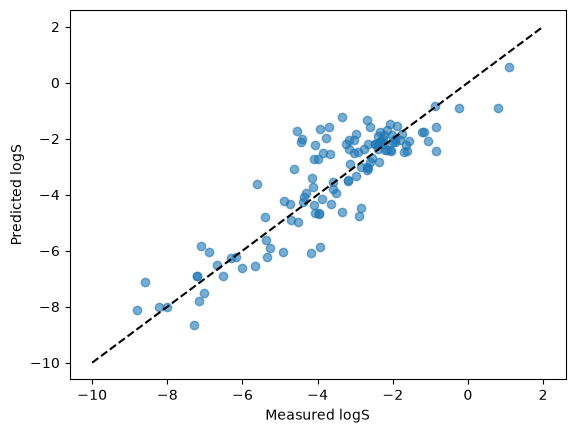

In [2]:
from train_esol import run
result=run(DATA/"esol.csv",OUT)
display(pd.json_normalize(result["splits"],sep="."))
assert result["rows"]==1128 and result["unique_identity"]==1117
for split in result["splits"].values():
    assert split["metrics"]["random_forest"]["MAE_logS"] < split["metrics"]["mean_baseline"]["MAE_logS"]
predictions=pd.read_csv(OUT/"scaffold_predictions.csv")
predictions["absolute_error"]=abs(predictions.measured_logS-predictions.predicted)
display(predictions.nlargest(5,"absolute_error"))
plt.scatter(predictions.measured_logS,predictions.predicted,alpha=0.6)
plt.plot([-10,2],[-10,2],"k--");plt.xlabel("Measured logS");plt.ylabel("Predicted logS")
plt.savefig(OUT/"parity.png",dpi=150);plt.show()
artifact=result


## 3. Проверяемая запись запуска

Benchmark фиксирует этот запуск. Время включает расчёт и создание артефактов, но не установку среды; это не сравнительный рейтинг оборудования.

In [3]:
elapsed = time.perf_counter()-started
run_record = {"lab": 11, "calculation_wall_seconds": elapsed, "result": artifact}
(OUT/"benchmark.json").write_text(json.dumps(run_record,ensure_ascii=False,indent=2),encoding="utf-8")
print("Запуск сохранён:",OUT/"benchmark.json")


Запуск сохранён: C:\Users\Miakhlov\Documents\GitHub\Computational chemistry_course\tmp\practice-audit-issue1-20261117\Labs\results\lab11\benchmark.json


## 4. Самостоятельная тренировка

1. Почему 20% групп не обязаны давать 20% строк?
2. Определите, какие записи дали крупнейшие ошибки; не удаляйте их из отчёта.
3. Добавьте повторный split только как новый заранее определённый эксперимент, без выбора самого красивого теста.

[Ответы после попытки](../solutions/lab11.md). Вернитесь к первому заданию через неделю.

## 5. Ваш научный вывод

1. Какой результат получен?
2. Какой вывод из него пока не следует?
3. Какой следующий эксперимент или контроль нужен?

Сохраните свой вариант notebook отдельно; исходный пример должен остаться воспроизводимым.